# Generate SVDs

In [1]:
import numpy as np
import sys
sys.path.append('/home/asyeda/Facemap/facemap/')
from facemap import process
from glob import glob
import os, cv2
import matplotlib.pyplot as plt
import os
%matplotlib inline

### Helper functions

In [2]:
# Function to update the displayed frame with ROI
"""
def update_display(roi):
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    x, y, w, h = roi
    frame_rgb = cv2.rectangle(frame_rgb, (x, y), (x + w, y + h), (0, 255, 0), 2)
    ax.imshow(frame_rgb)
    plt.draw()

# Function to display video frames with ROI using Matplotlib
def display_video_with_roi(video_path, roi):
    global frame, ax

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Error: Cannot open video file.")
        return

    ret, frame = cap.read()
    if not ret:
        print("Error: Cannot read video file.")
        cap.release()
        return

    fig, ax = plt.subplots(1)
    update_display(roi)
    plt.show()
    cap.release()
"""
# Function to update display with multiple ROIs
def update_display(frame, rois):
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    for roi in rois:
        x, y, w, h = roi
        cv2.rectangle(frame_rgb, (x, y), (x + w, y + h), (0, 255, 0), 2)
    ax.imshow(frame_rgb)
    plt.draw()

# Function to display video frames with multiple ROIs using Matplotlib
def display_video_with_rois(video_path, rois):
    global frame, ax

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Error: Cannot open video file.")
        return

    ret, frame = cap.read()
    if not ret:
        print("Error: Cannot read video file.")
        cap.release()
        return

    fig, ax = plt.subplots(1)
    update_display(frame, rois)
    plt.show()
    cap.release()

# Function to crop and save the video based on ROI
def crop_and_save_video(video_path, output_path, roi_x, roi_y, roi_w, roi_h):
    # Open the video file
    cap = cv2.VideoCapture(video_path)
    out_dir = os.path.dirname(output_path)
    if out_dir and not os.path.exists(out_dir):
        raise FileNotFoundError(f"Output directory does not exist: {out_dir}")

    if out_dir and not os.access(out_dir, os.W_OK):
        raise PermissionError(f"No write permission for directory: {out_dir}")

    if not cap.isOpened():
        print("Error: Could not open video.")
        return
    
    # Get the video properties
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Define the codec and create VideoWriter object
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # You can use other codecs as well, like 'XVID', 'MJPG', etc.
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        
        # Create a mask for the ROI
        mask = np.zeros_like(frame)
        mask[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w] = frame[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w]
        
        # Write the frame with ROI to the output video
        out.write(mask)

    # Release everything when done
    cap.release()
    out.release()

# Function to crop and save the video based on ROI while maintaining resolution
def process_and_save_video(video_path, output_path, crop_roi, zero_roi):
    # Open the video file
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        print("Error: Could not open video.")
        return
    
    # Get the video properties
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Define the codec and create VideoWriter object
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # You can use other codecs as well, like 'XVID', 'MJPG', etc.
    out = cv2.VideoWriter(output_path, fourcc, fps, (crop_roi[2], crop_roi[3]))

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
                
        # Set the pixels within the second ROI to zero
        zero_x, zero_y, zero_w, zero_h = zero_roi
        frame[zero_y:zero_y + zero_h, zero_x:zero_x + zero_w] = 0

        # Crop the frame based on the first ROI coordinates
        cropped_frame = frame[crop_roi[1]:crop_roi[1] + crop_roi[3], crop_roi[0]:crop_roi[0] + crop_roi[2]]
        
        # Write the processed frame to the output video
        out.write(cropped_frame)

    # Release everything when done
    cap.release()
    out.release()

## Process full face video SVD

### Set variables

In [35]:
video_path = '/home/asyeda/nas113/Atika/'
mouse = 'FXa8'
session = '2026_01_16'
blk = ['1']

video_files = []
for b in blk:
    v = glob(os.path.join(video_path, "{m}/{s}/{b}/{m}_{s}_{b}_*full.mp4".format(m=mouse, s=session, b=b)))
    video_files.extend(v)
video_files

['/home/asyeda/nas113/Atika/FXa8/2026_01_16/1/FXa8_2026_01_16_1_full.mp4']

In [3]:
video_files = ['/home/asyeda/stringerlab_dm11/eye-vs-face/data/VG_data/behavior/2026_10_21/5/VG56_2026_10_21_5_full.mp4']
video_path = os.path.dirname(video_files[0])
mouse, session, blk = 'VG56', '2026_10_21', '5'
video_path, video_files

('/home/asyeda/stringerlab_dm11/eye-vs-face/data/VG_data/behavior/2026_10_21/5',
 ['/home/asyeda/stringerlab_dm11/eye-vs-face/data/VG_data/behavior/2026_10_21/5/VG56_2026_10_21_5_full.mp4'])

### Select face ROI

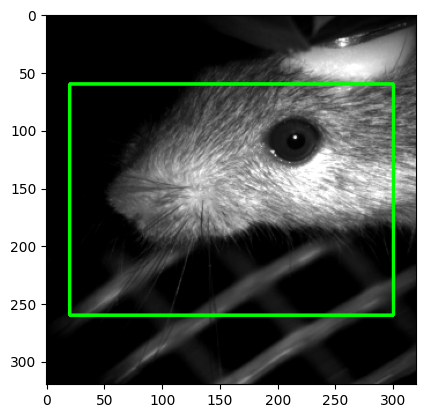

In [4]:
# Display the video with ROI
roi = [[20, 60, 280, 200]] #[[20, 45, 220, 190]] # [x, y, w, h]
ax, frame = None, None
for video in video_files:
    display_video_with_rois(video, roi)

### Select face + eye ROI

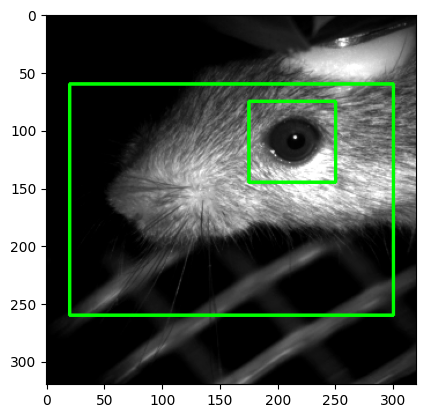

In [12]:
# Define two rectangles ROIs as (x, y, width, height)
full_face_roi = roi[0]
eye_roi = [175, 75, 75, 70]
rois = [full_face_roi, eye_roi]

ax, frame = None, None
for video in video_files:
    display_video_with_rois(video, rois)

### Crop video and save

In [13]:
roi_x, roi_y, roi_w, roi_h = full_face_roi
for video in video_files:
    output_path = video.replace('full', 'fullface')  # Output video path
    crop_and_save_video(video, output_path, roi_x, roi_y, roi_w, roi_h)

In [14]:
for video in video_files:
    output_path = video.replace('full', 'face-eye')  
    process_and_save_video(video, output_path, full_face_roi, eye_roi)

In [15]:
# Save ROI
np.save(os.path.join(video_path, '{m}_{s}_{b}_roi.npy'.format(m=mouse, s=session, b=blk[0])), {'full_face': full_face_roi, 'eye': eye_roi})

### Process and save SVD

In [16]:
fullface_video_list = []
face_eye_video_list = []
for video in video_files:
    v = video.replace('full', 'fullface')
    fullface_video_list.append([v])
    v = video.replace('full', 'face-eye')
    face_eye_video_list.append([v])

In [17]:
face_eye_video_list, fullface_video_list

([['/home/asyeda/stringerlab_dm11/eye-vs-face/data/VG_data/behavior/2026_10_21/5/VG56_2026_10_21_5_face-eye.mp4']],
 [['/home/asyeda/stringerlab_dm11/eye-vs-face/data/VG_data/behavior/2026_10_21/5/VG56_2026_10_21_5_fullface.mp4']])

In [18]:
savename = process.run(face_eye_video_list, motSVD=True, movSVD=True)
print("Output saved in", savename)

Computing subsampled mean...
Computed subsampled mean at 0.45s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.76sec
computed svd chunk 1 / 15, time  7.30sec
computed svd chunk 2 / 15, time  13.31sec
computed svd chunk 3 / 15, time  18.76sec
computed svd chunk 4 / 15, time  24.64sec
computed svd chunk 5 / 15, time  30.07sec
computed svd chunk 6 / 15, time  35.54sec
computed svd chunk 7 / 15, time  41.55sec
computed svd chunk 8 / 15, time  47.89sec
computed svd chunk 9 / 15, time  53.63sec
computed svd chunk 10 / 15, time  59.40sec
computed svd chunk 11 / 15, time  64.98sec
computed svd chunk 12 / 15, time  70.43sec
computed svd chunk 13 / 15, time  75.67sec
computed svd chunk 14 / 15, time  81.61sec
Computed subsampled SVD at 98.56s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 411, time  99.17sec
computed video chunk 10 / 411, time  104.21sec
computed video chunk 20 / 411, time  109.26sec
computed video chunk 30 / 411, time  114.29sec
computed video chunk

In [19]:
savename = process.run(fullface_video_list, motSVD=True, movSVD=True)
print("Output saved in", savename)

Computing subsampled mean...
Computed subsampled mean at 0.66s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  2.52sec
computed svd chunk 1 / 15, time  12.07sec
computed svd chunk 2 / 15, time  21.48sec
computed svd chunk 3 / 15, time  31.00sec
computed svd chunk 4 / 15, time  40.09sec
computed svd chunk 5 / 15, time  49.37sec
computed svd chunk 6 / 15, time  58.37sec
computed svd chunk 7 / 15, time  67.51sec
computed svd chunk 8 / 15, time  76.86sec
computed svd chunk 9 / 15, time  86.39sec
computed svd chunk 10 / 15, time  95.61sec
computed svd chunk 11 / 15, time  104.99sec
computed svd chunk 12 / 15, time  114.16sec
computed svd chunk 13 / 15, time  123.34sec
computed svd chunk 14 / 15, time  132.69sec
Computed subsampled SVD at 157.22s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 411, time  158.88sec
computed video chunk 10 / 411, time  173.73sec
computed video chunk 20 / 411, time  188.07sec
computed video chunk 30 / 411, time  202.57sec
computed vide

## Process small eye video svd

In [3]:
data_path = '/home/asyeda/stringerlab_dm11/eye-vs-face/data/cam_data'  

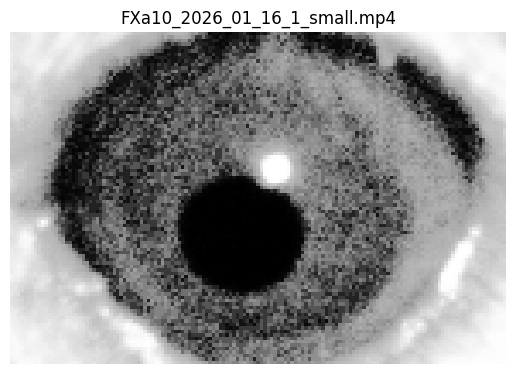

Computing subsampled mean...
Computed subsampled mean at 0.70s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.41sec
computed svd chunk 1 / 15, time  9.16sec
computed svd chunk 2 / 15, time  19.25sec
computed svd chunk 3 / 15, time  28.90sec
computed svd chunk 4 / 15, time  37.69sec
computed svd chunk 5 / 15, time  46.72sec
computed svd chunk 6 / 15, time  55.61sec
computed svd chunk 7 / 15, time  64.16sec
computed svd chunk 8 / 15, time  72.19sec
computed svd chunk 9 / 15, time  82.12sec
computed svd chunk 10 / 15, time  91.87sec
computed svd chunk 11 / 15, time  100.63sec
computed svd chunk 12 / 15, time  109.37sec
computed svd chunk 13 / 15, time  118.24sec
computed svd chunk 14 / 15, time  126.49sec
Computed subsampled SVD at 156.16s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 548, time  156.33sec
computed video chunk 10 / 548, time  157.89sec
computed video chunk 20 / 548, time  159.35sec
computed video chunk 30 / 548, time  160.89sec
computed video

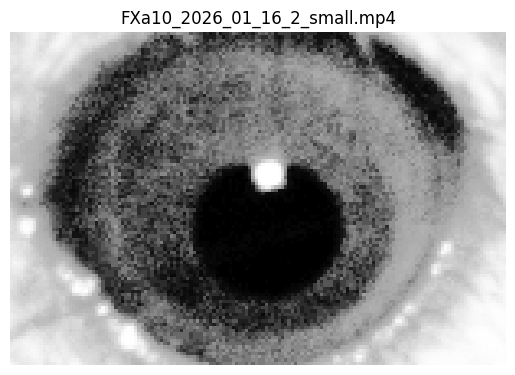

Computing subsampled mean...
Computed subsampled mean at 0.72s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.43sec
computed svd chunk 1 / 15, time  10.62sec
computed svd chunk 2 / 15, time  20.07sec
computed svd chunk 3 / 15, time  30.01sec
computed svd chunk 4 / 15, time  39.53sec
computed svd chunk 5 / 15, time  49.02sec
computed svd chunk 6 / 15, time  57.71sec
computed svd chunk 7 / 15, time  65.91sec
computed svd chunk 8 / 15, time  74.78sec
computed svd chunk 9 / 15, time  83.53sec
computed svd chunk 10 / 15, time  92.23sec
computed svd chunk 11 / 15, time  101.16sec
computed svd chunk 12 / 15, time  109.18sec
computed svd chunk 13 / 15, time  117.92sec
computed svd chunk 14 / 15, time  126.96sec
Computed subsampled SVD at 156.19s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 65, time  156.39sec
computed video chunk 10 / 65, time  158.13sec
computed video chunk 20 / 65, time  159.80sec
computed video chunk 30 / 65, time  161.41sec
computed video ch

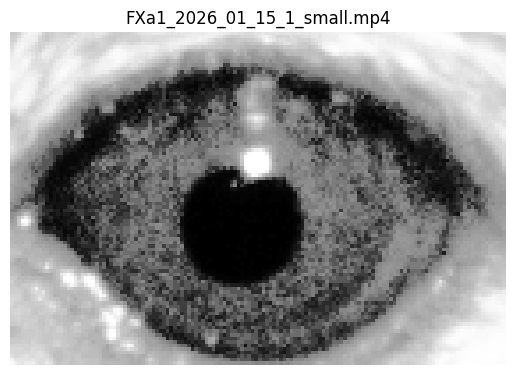

Computing subsampled mean...
Computed subsampled mean at 0.60s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.37sec
computed svd chunk 1 / 15, time  9.38sec
computed svd chunk 2 / 15, time  17.72sec
computed svd chunk 3 / 15, time  26.70sec
computed svd chunk 4 / 15, time  35.44sec
computed svd chunk 5 / 15, time  44.62sec
computed svd chunk 6 / 15, time  52.84sec
computed svd chunk 7 / 15, time  61.55sec
computed svd chunk 8 / 15, time  70.24sec
computed svd chunk 9 / 15, time  78.78sec
computed svd chunk 10 / 15, time  87.54sec
computed svd chunk 11 / 15, time  96.35sec
computed svd chunk 12 / 15, time  105.61sec
computed svd chunk 13 / 15, time  113.69sec
computed svd chunk 14 / 15, time  122.04sec
Computed subsampled SVD at 150.45s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 545, time  150.64sec
computed video chunk 10 / 545, time  152.14sec
computed video chunk 20 / 545, time  153.69sec
computed video chunk 30 / 545, time  155.17sec
computed video 

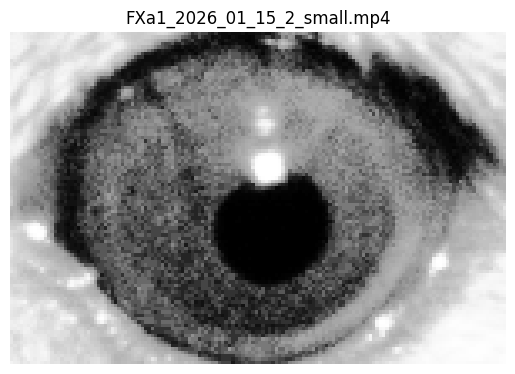

Computing subsampled mean...
Computed subsampled mean at 0.75s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.46sec
computed svd chunk 1 / 15, time  10.03sec
computed svd chunk 2 / 15, time  19.13sec
computed svd chunk 3 / 15, time  28.46sec
computed svd chunk 4 / 15, time  37.67sec
computed svd chunk 5 / 15, time  46.43sec
computed svd chunk 6 / 15, time  55.62sec
computed svd chunk 7 / 15, time  64.54sec
computed svd chunk 8 / 15, time  72.59sec
computed svd chunk 9 / 15, time  81.17sec
computed svd chunk 10 / 15, time  89.99sec
computed svd chunk 11 / 15, time  98.24sec
computed svd chunk 12 / 15, time  106.85sec
computed svd chunk 13 / 15, time  115.33sec
computed svd chunk 14 / 15, time  124.01sec
Computed subsampled SVD at 154.14s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 65, time  154.38sec
computed video chunk 10 / 65, time  156.09sec
computed video chunk 20 / 65, time  157.76sec
computed video chunk 30 / 65, time  159.34sec
computed video chu

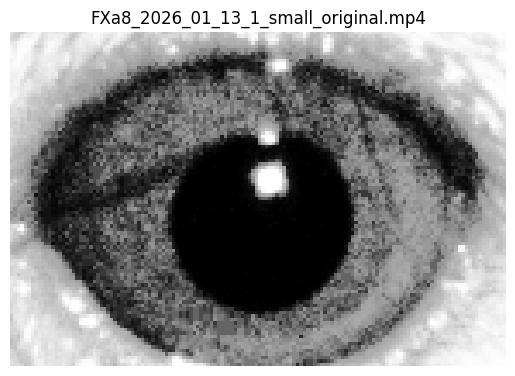

Computing subsampled mean...
Computed subsampled mean at 0.66s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.40sec
computed svd chunk 1 / 15, time  10.26sec
computed svd chunk 2 / 15, time  18.78sec
computed svd chunk 3 / 15, time  27.53sec
computed svd chunk 4 / 15, time  36.73sec
computed svd chunk 5 / 15, time  45.29sec
computed svd chunk 6 / 15, time  53.84sec
computed svd chunk 7 / 15, time  62.19sec
computed svd chunk 8 / 15, time  71.30sec
computed svd chunk 9 / 15, time  79.92sec
computed svd chunk 10 / 15, time  89.30sec
computed svd chunk 11 / 15, time  98.34sec
computed svd chunk 12 / 15, time  106.94sec
computed svd chunk 13 / 15, time  115.04sec
computed svd chunk 14 / 15, time  123.16sec
Computed subsampled SVD at 153.15s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 543, time  153.32sec
computed video chunk 10 / 543, time  154.96sec
computed video chunk 20 / 543, time  156.43sec
computed video chunk 30 / 543, time  157.79sec
computed video

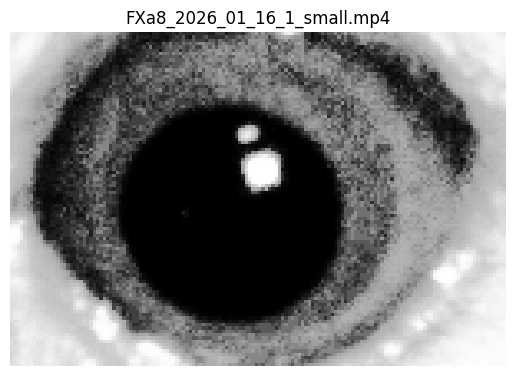

Computing subsampled mean...
Computed subsampled mean at 0.71s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.42sec
computed svd chunk 1 / 15, time  9.97sec
computed svd chunk 2 / 15, time  18.77sec
computed svd chunk 3 / 15, time  26.50sec
computed svd chunk 4 / 15, time  35.12sec
computed svd chunk 5 / 15, time  42.23sec
computed svd chunk 6 / 15, time  51.23sec
computed svd chunk 7 / 15, time  59.93sec
computed svd chunk 8 / 15, time  69.06sec
computed svd chunk 9 / 15, time  77.88sec
computed svd chunk 10 / 15, time  85.73sec
computed svd chunk 11 / 15, time  92.37sec
computed svd chunk 12 / 15, time  97.91sec
computed svd chunk 13 / 15, time  106.01sec
computed svd chunk 14 / 15, time  109.93sec
Computed subsampled SVD at 130.98s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 549, time  131.18sec
computed video chunk 10 / 549, time  132.84sec
computed video chunk 20 / 549, time  134.50sec
computed video chunk 30 / 549, time  136.14sec
computed video c

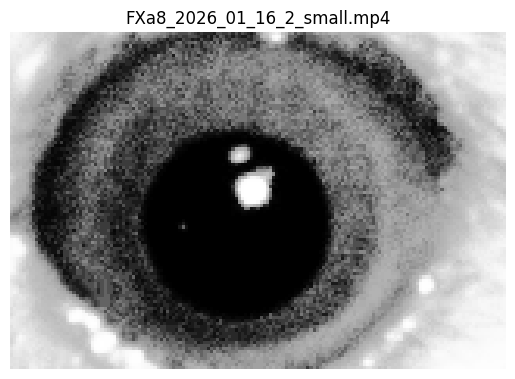

Computing subsampled mean...
Computed subsampled mean at 0.79s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.44sec
computed svd chunk 1 / 15, time  8.43sec
computed svd chunk 2 / 15, time  16.15sec
computed svd chunk 3 / 15, time  25.84sec
computed svd chunk 4 / 15, time  34.53sec
computed svd chunk 5 / 15, time  42.37sec
computed svd chunk 6 / 15, time  47.58sec
computed svd chunk 7 / 15, time  54.11sec
computed svd chunk 8 / 15, time  60.80sec
computed svd chunk 9 / 15, time  67.38sec
computed svd chunk 10 / 15, time  74.65sec
computed svd chunk 11 / 15, time  79.62sec
computed svd chunk 12 / 15, time  87.37sec
computed svd chunk 13 / 15, time  95.14sec
computed svd chunk 14 / 15, time  103.06sec
Computed subsampled SVD at 122.44s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 65, time  122.73sec
computed video chunk 10 / 65, time  124.97sec
computed video chunk 20 / 65, time  127.04sec
computed video chunk 30 / 65, time  128.98sec
computed video chunk 

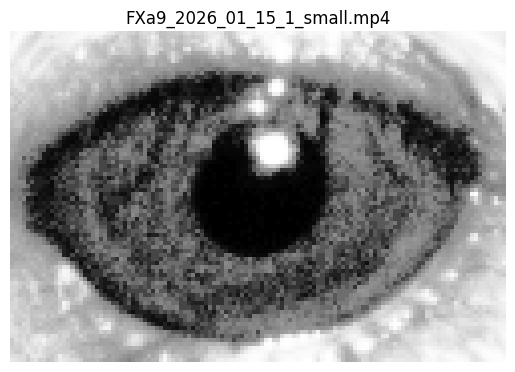

Computing subsampled mean...
Computed subsampled mean at 0.57s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.30sec
computed svd chunk 1 / 15, time  7.47sec
computed svd chunk 2 / 15, time  13.57sec
computed svd chunk 3 / 15, time  19.87sec
computed svd chunk 4 / 15, time  24.12sec
computed svd chunk 5 / 15, time  31.49sec
computed svd chunk 6 / 15, time  37.30sec
computed svd chunk 7 / 15, time  45.79sec
computed svd chunk 8 / 15, time  53.04sec
computed svd chunk 9 / 15, time  60.06sec
computed svd chunk 10 / 15, time  67.72sec
computed svd chunk 11 / 15, time  75.48sec
computed svd chunk 12 / 15, time  82.49sec
computed svd chunk 13 / 15, time  88.13sec
computed svd chunk 14 / 15, time  93.10sec
Computed subsampled SVD at 109.19s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 544, time  109.32sec
computed video chunk 10 / 544, time  110.51sec
computed video chunk 20 / 544, time  111.52sec
computed video chunk 30 / 544, time  112.58sec
computed video chu

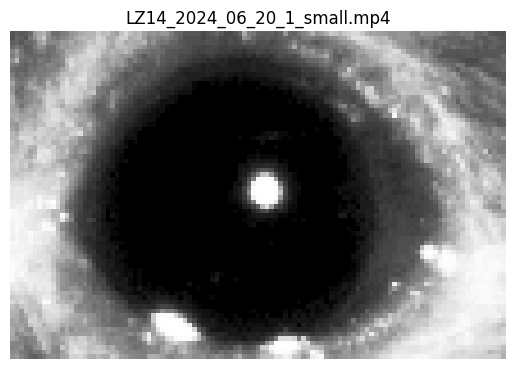

Computing subsampled mean...
Computed subsampled mean at 0.46s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.26sec
computed svd chunk 1 / 15, time  7.07sec
computed svd chunk 2 / 15, time  13.69sec
computed svd chunk 3 / 15, time  20.42sec
computed svd chunk 4 / 15, time  26.82sec
computed svd chunk 5 / 15, time  33.45sec
computed svd chunk 6 / 15, time  38.39sec
computed svd chunk 7 / 15, time  43.37sec
computed svd chunk 8 / 15, time  48.46sec
computed svd chunk 9 / 15, time  53.79sec
computed svd chunk 10 / 15, time  60.12sec
computed svd chunk 11 / 15, time  65.31sec
computed svd chunk 12 / 15, time  69.53sec
computed svd chunk 13 / 15, time  75.83sec
computed svd chunk 14 / 15, time  80.58sec
Computed subsampled SVD at 101.71s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 137, time  101.83sec
computed video chunk 10 / 137, time  102.83sec
computed video chunk 20 / 137, time  103.70sec
computed video chunk 30 / 137, time  104.56sec
computed video chu

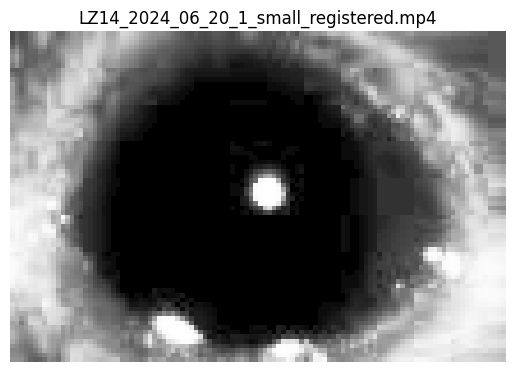

Computing subsampled mean...
Computed subsampled mean at 0.15s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.16sec
computed svd chunk 1 / 15, time  6.10sec
computed svd chunk 2 / 15, time  12.24sec
computed svd chunk 3 / 15, time  17.42sec
computed svd chunk 4 / 15, time  23.68sec
computed svd chunk 5 / 15, time  30.41sec
computed svd chunk 6 / 15, time  34.86sec
computed svd chunk 7 / 15, time  40.23sec
computed svd chunk 8 / 15, time  46.28sec
computed svd chunk 9 / 15, time  51.01sec
computed svd chunk 10 / 15, time  56.64sec
computed svd chunk 11 / 15, time  62.59sec
computed svd chunk 12 / 15, time  67.98sec
computed svd chunk 13 / 15, time  74.86sec
computed svd chunk 14 / 15, time  79.13sec
Computed subsampled SVD at 96.26s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 137, time  96.37sec
computed video chunk 10 / 137, time  97.14sec
computed video chunk 20 / 137, time  97.95sec
computed video chunk 30 / 137, time  98.70sec
computed video chunk 40

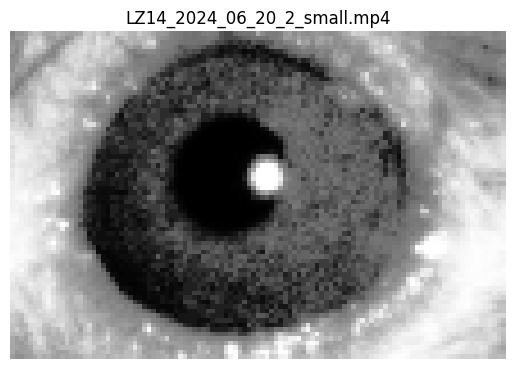

Computing subsampled mean...
Computed subsampled mean at 0.53s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.28sec
computed svd chunk 1 / 15, time  4.31sec
computed svd chunk 2 / 15, time  8.82sec
computed svd chunk 3 / 15, time  15.29sec
computed svd chunk 4 / 15, time  21.28sec
computed svd chunk 5 / 15, time  27.72sec
computed svd chunk 6 / 15, time  32.83sec
computed svd chunk 7 / 15, time  39.17sec
computed svd chunk 8 / 15, time  43.03sec
computed svd chunk 9 / 15, time  48.57sec
computed svd chunk 10 / 15, time  54.30sec
computed svd chunk 11 / 15, time  57.59sec
computed svd chunk 12 / 15, time  63.32sec
computed svd chunk 13 / 15, time  68.71sec
computed svd chunk 14 / 15, time  74.04sec
Computed subsampled SVD at 92.70s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 270, time  92.82sec
computed video chunk 10 / 270, time  93.84sec
computed video chunk 20 / 270, time  94.72sec
computed video chunk 30 / 270, time  95.62sec
computed video chunk 40 

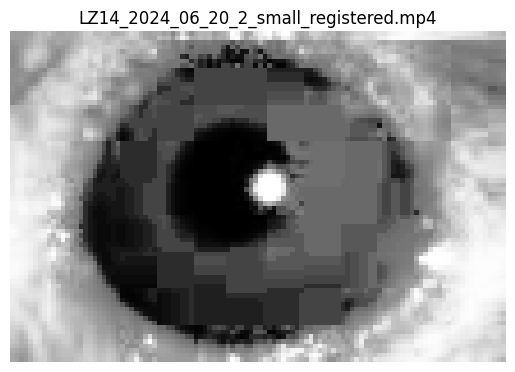

Computing subsampled mean...
Computed subsampled mean at 0.17s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.18sec
computed svd chunk 1 / 15, time  6.50sec
computed svd chunk 2 / 15, time  12.63sec
computed svd chunk 3 / 15, time  18.76sec
computed svd chunk 4 / 15, time  25.06sec
computed svd chunk 5 / 15, time  29.91sec
computed svd chunk 6 / 15, time  35.15sec
computed svd chunk 7 / 15, time  41.55sec
computed svd chunk 8 / 15, time  47.91sec
computed svd chunk 9 / 15, time  52.72sec
computed svd chunk 10 / 15, time  57.40sec
computed svd chunk 11 / 15, time  63.95sec
computed svd chunk 12 / 15, time  68.73sec
computed svd chunk 13 / 15, time  75.07sec
computed svd chunk 14 / 15, time  81.55sec
Computed subsampled SVD at 97.10s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 270, time  97.20sec
computed video chunk 10 / 270, time  98.03sec
computed video chunk 20 / 270, time  98.89sec
computed video chunk 30 / 270, time  99.73sec
computed video chunk 40

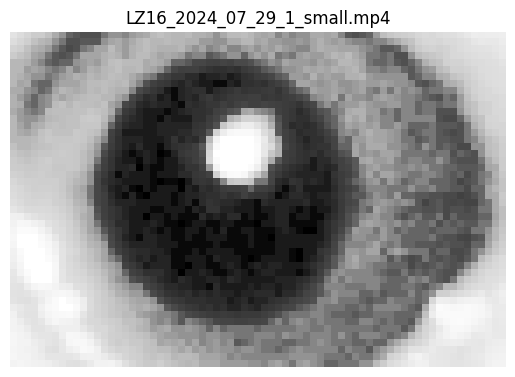

Computing subsampled mean...
Computed subsampled mean at 0.33s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.16sec
computed svd chunk 1 / 15, time  3.76sec
computed svd chunk 2 / 15, time  9.26sec
computed svd chunk 3 / 15, time  14.43sec
computed svd chunk 4 / 15, time  20.36sec
computed svd chunk 5 / 15, time  25.40sec
computed svd chunk 6 / 15, time  30.59sec
computed svd chunk 7 / 15, time  35.63sec
computed svd chunk 8 / 15, time  40.53sec
computed svd chunk 9 / 15, time  47.28sec
computed svd chunk 10 / 15, time  52.64sec
computed svd chunk 11 / 15, time  57.97sec
computed svd chunk 12 / 15, time  64.86sec
computed svd chunk 13 / 15, time  71.63sec
computed svd chunk 14 / 15, time  75.91sec
Computed subsampled SVD at 89.92s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 404, time  90.02sec
computed video chunk 10 / 404, time  90.61sec
computed video chunk 20 / 404, time  91.19sec
computed video chunk 30 / 404, time  91.74sec
computed video chunk 40 

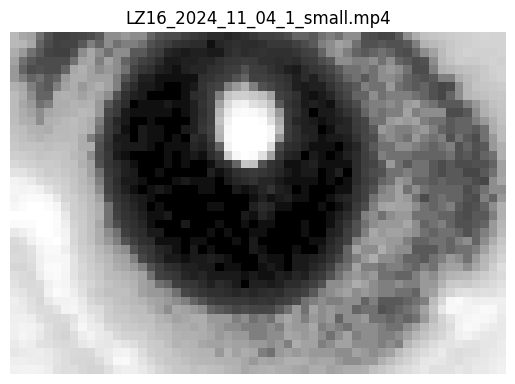

Computing subsampled mean...
Computed subsampled mean at 0.24s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.13sec
computed svd chunk 1 / 15, time  3.18sec
computed svd chunk 2 / 15, time  6.03sec
computed svd chunk 3 / 15, time  10.27sec
computed svd chunk 4 / 15, time  15.10sec
computed svd chunk 5 / 15, time  20.00sec
computed svd chunk 6 / 15, time  24.78sec
computed svd chunk 7 / 15, time  29.42sec
computed svd chunk 8 / 15, time  31.67sec
computed svd chunk 9 / 15, time  35.77sec
computed svd chunk 10 / 15, time  40.44sec
computed svd chunk 11 / 15, time  44.94sec
computed svd chunk 12 / 15, time  46.81sec
computed svd chunk 13 / 15, time  51.68sec
computed svd chunk 14 / 15, time  56.82sec
Computed subsampled SVD at 71.91s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 428, time  72.01sec
computed video chunk 10 / 428, time  72.56sec
computed video chunk 20 / 428, time  73.08sec
computed video chunk 30 / 428, time  73.56sec
computed video chunk 40 

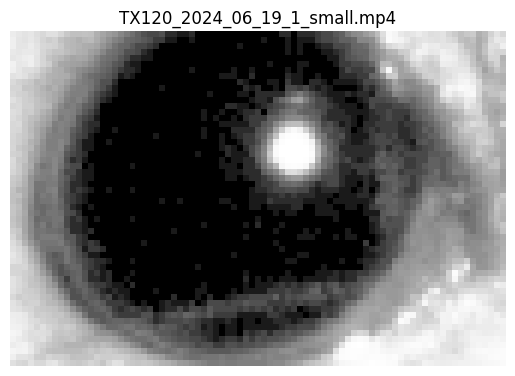

Computing subsampled mean...
Computed subsampled mean at 0.41s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.20sec
computed svd chunk 1 / 15, time  5.64sec
computed svd chunk 2 / 15, time  11.41sec
computed svd chunk 3 / 15, time  16.71sec
computed svd chunk 4 / 15, time  22.18sec
computed svd chunk 5 / 15, time  27.89sec
computed svd chunk 6 / 15, time  33.58sec
computed svd chunk 7 / 15, time  39.10sec
computed svd chunk 8 / 15, time  44.59sec
computed svd chunk 9 / 15, time  51.24sec
computed svd chunk 10 / 15, time  55.54sec
computed svd chunk 11 / 15, time  61.04sec
computed svd chunk 12 / 15, time  67.07sec
computed svd chunk 13 / 15, time  72.82sec
computed svd chunk 14 / 15, time  78.74sec
Computed subsampled SVD at 100.42s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 142, time  100.52sec
computed video chunk 10 / 142, time  101.18sec
computed video chunk 20 / 142, time  101.87sec
computed video chunk 30 / 142, time  102.47sec
computed video chu

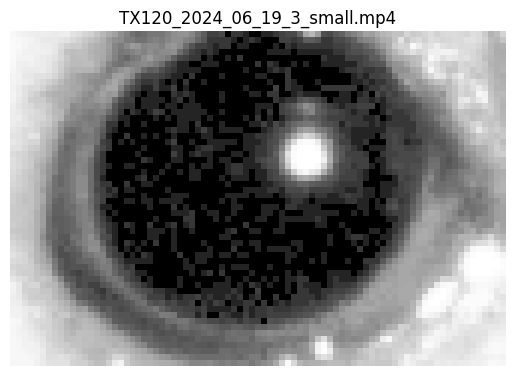

Computing subsampled mean...
Computed subsampled mean at 0.40s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.21sec
computed svd chunk 1 / 15, time  5.93sec
computed svd chunk 2 / 15, time  11.79sec
computed svd chunk 3 / 15, time  17.81sec
computed svd chunk 4 / 15, time  23.75sec
computed svd chunk 5 / 15, time  29.86sec
computed svd chunk 6 / 15, time  35.47sec
computed svd chunk 7 / 15, time  41.28sec
computed svd chunk 8 / 15, time  47.23sec
computed svd chunk 9 / 15, time  54.21sec
computed svd chunk 10 / 15, time  60.98sec
computed svd chunk 11 / 15, time  66.53sec
computed svd chunk 12 / 15, time  72.26sec
computed svd chunk 13 / 15, time  78.01sec
computed svd chunk 14 / 15, time  83.66sec
Computed subsampled SVD at 102.79s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 100, time  102.89sec
computed video chunk 10 / 100, time  103.63sec
computed video chunk 20 / 100, time  104.32sec
computed video chunk 30 / 100, time  105.06sec
computed video chu

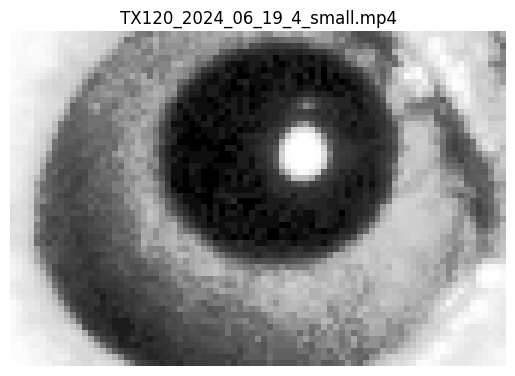

Computing subsampled mean...
Computed subsampled mean at 0.40s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.21sec
computed svd chunk 1 / 15, time  6.18sec
computed svd chunk 2 / 15, time  12.08sec
computed svd chunk 3 / 15, time  17.93sec
computed svd chunk 4 / 15, time  24.11sec
computed svd chunk 5 / 15, time  30.63sec
computed svd chunk 6 / 15, time  37.90sec
computed svd chunk 7 / 15, time  43.99sec
computed svd chunk 8 / 15, time  49.98sec
computed svd chunk 9 / 15, time  55.72sec
computed svd chunk 10 / 15, time  62.17sec
computed svd chunk 11 / 15, time  67.45sec
computed svd chunk 12 / 15, time  73.89sec
computed svd chunk 13 / 15, time  79.32sec
computed svd chunk 14 / 15, time  85.31sec
Computed subsampled SVD at 105.40s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 166, time  105.50sec
computed video chunk 10 / 166, time  106.18sec
computed video chunk 20 / 166, time  106.89sec
computed video chunk 30 / 166, time  107.55sec
computed video chu

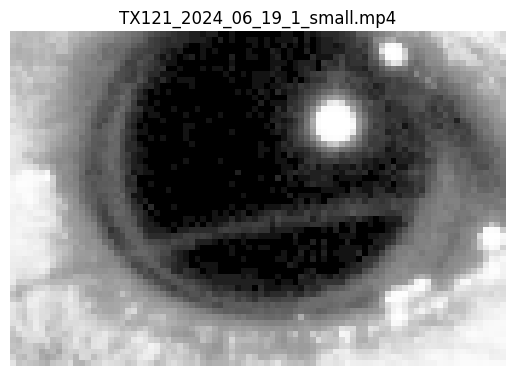

Computing subsampled mean...
Computed subsampled mean at 0.45s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.20sec
computed svd chunk 1 / 15, time  6.46sec
computed svd chunk 2 / 15, time  12.06sec
computed svd chunk 3 / 15, time  17.75sec
computed svd chunk 4 / 15, time  23.86sec
computed svd chunk 5 / 15, time  30.06sec
computed svd chunk 6 / 15, time  36.19sec
computed svd chunk 7 / 15, time  41.83sec
computed svd chunk 8 / 15, time  47.84sec
computed svd chunk 9 / 15, time  53.75sec
computed svd chunk 10 / 15, time  59.58sec
computed svd chunk 11 / 15, time  65.53sec
computed svd chunk 12 / 15, time  71.73sec
computed svd chunk 13 / 15, time  79.06sec
computed svd chunk 14 / 15, time  85.29sec
Computed subsampled SVD at 108.76s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 169, time  108.86sec
computed video chunk 10 / 169, time  109.60sec
computed video chunk 20 / 169, time  110.39sec
computed video chunk 30 / 169, time  111.15sec
computed video chu

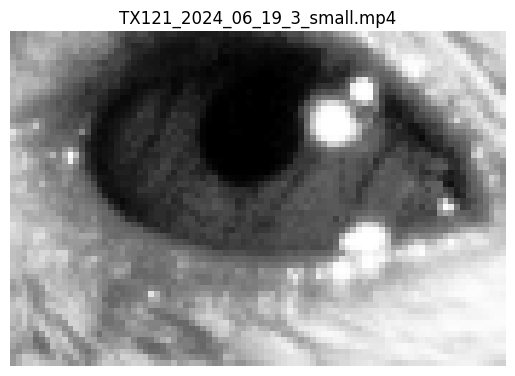

Computing subsampled mean...
Computed subsampled mean at 0.39s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.24sec
computed svd chunk 1 / 15, time  6.80sec
computed svd chunk 2 / 15, time  12.78sec
computed svd chunk 3 / 15, time  18.41sec
computed svd chunk 4 / 15, time  24.55sec
computed svd chunk 5 / 15, time  30.79sec
computed svd chunk 6 / 15, time  37.58sec
computed svd chunk 7 / 15, time  44.50sec
computed svd chunk 8 / 15, time  50.68sec
computed svd chunk 9 / 15, time  56.97sec
computed svd chunk 10 / 15, time  62.58sec
computed svd chunk 11 / 15, time  69.04sec
computed svd chunk 12 / 15, time  74.84sec
computed svd chunk 13 / 15, time  80.62sec
computed svd chunk 14 / 15, time  86.81sec
Computed subsampled SVD at 111.95s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 209, time  112.06sec
computed video chunk 10 / 209, time  112.78sec
computed video chunk 20 / 209, time  113.48sec
computed video chunk 30 / 209, time  114.17sec
computed video chu

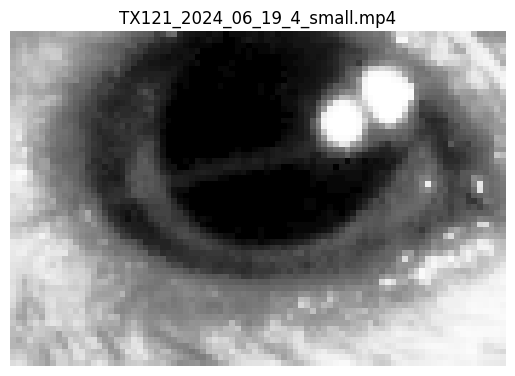

Computing subsampled mean...
Computed subsampled mean at 0.44s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.20sec
computed svd chunk 1 / 15, time  6.75sec
computed svd chunk 2 / 15, time  12.65sec
computed svd chunk 3 / 15, time  18.99sec
computed svd chunk 4 / 15, time  25.46sec
computed svd chunk 5 / 15, time  33.01sec
computed svd chunk 6 / 15, time  38.93sec
computed svd chunk 7 / 15, time  45.24sec
computed svd chunk 8 / 15, time  52.75sec
computed svd chunk 9 / 15, time  58.98sec
computed svd chunk 10 / 15, time  65.55sec
computed svd chunk 11 / 15, time  71.96sec
computed svd chunk 12 / 15, time  78.11sec
computed svd chunk 13 / 15, time  84.42sec
computed svd chunk 14 / 15, time  90.44sec
Computed subsampled SVD at 112.85s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 69, time  112.96sec
computed video chunk 10 / 69, time  113.67sec
computed video chunk 20 / 69, time  114.42sec
computed video chunk 30 / 69, time  115.12sec
computed video chunk 4

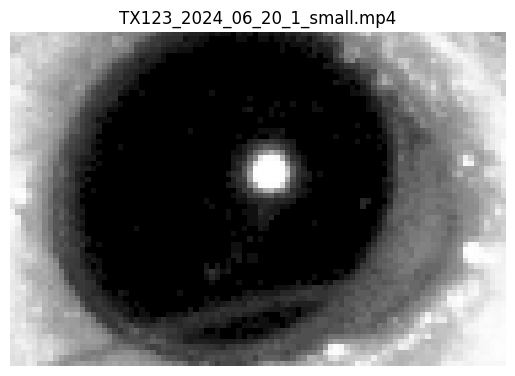

Computing subsampled mean...
Computed subsampled mean at 0.37s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.19sec
computed svd chunk 1 / 15, time  6.85sec
computed svd chunk 2 / 15, time  14.85sec
computed svd chunk 3 / 15, time  21.10sec
computed svd chunk 4 / 15, time  28.88sec
computed svd chunk 5 / 15, time  35.08sec
computed svd chunk 6 / 15, time  41.31sec
computed svd chunk 7 / 15, time  49.00sec
computed svd chunk 8 / 15, time  55.22sec
computed svd chunk 9 / 15, time  62.27sec
computed svd chunk 10 / 15, time  69.95sec
computed svd chunk 11 / 15, time  75.99sec
computed svd chunk 12 / 15, time  82.25sec
computed svd chunk 13 / 15, time  90.12sec
computed svd chunk 14 / 15, time  96.57sec
Computed subsampled SVD at 122.50s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 149, time  122.60sec
computed video chunk 10 / 149, time  123.31sec
computed video chunk 20 / 149, time  124.08sec
computed video chunk 30 / 149, time  124.83sec
computed video chu

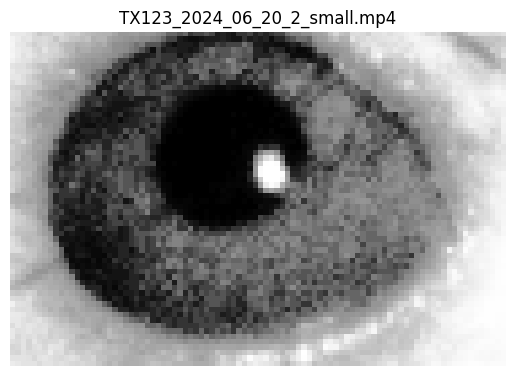

Computing subsampled mean...
Computed subsampled mean at 0.44s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.24sec
computed svd chunk 1 / 15, time  6.84sec
computed svd chunk 2 / 15, time  13.19sec
computed svd chunk 3 / 15, time  19.81sec
computed svd chunk 4 / 15, time  26.16sec
computed svd chunk 5 / 15, time  32.35sec
computed svd chunk 6 / 15, time  38.67sec
computed svd chunk 7 / 15, time  44.91sec
computed svd chunk 8 / 15, time  50.96sec
computed svd chunk 9 / 15, time  57.39sec
computed svd chunk 10 / 15, time  63.67sec
computed svd chunk 11 / 15, time  70.60sec
computed svd chunk 12 / 15, time  77.52sec
computed svd chunk 13 / 15, time  83.68sec
computed svd chunk 14 / 15, time  89.99sec
Computed subsampled SVD at 115.97s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 214, time  116.08sec
computed video chunk 10 / 214, time  116.87sec
computed video chunk 20 / 214, time  117.61sec
computed video chunk 30 / 214, time  118.34sec
computed video chu

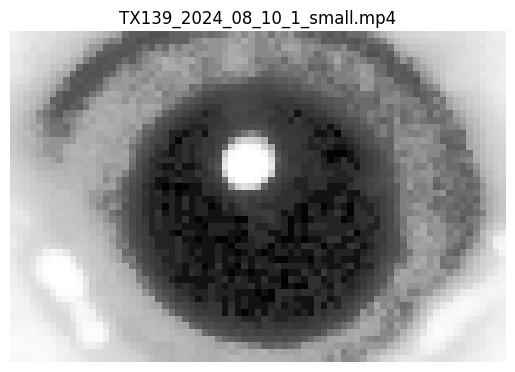

Computing subsampled mean...
Computed subsampled mean at 0.31s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.16sec
computed svd chunk 1 / 15, time  5.45sec
computed svd chunk 2 / 15, time  11.37sec
computed svd chunk 3 / 15, time  17.37sec
computed svd chunk 4 / 15, time  22.78sec
computed svd chunk 5 / 15, time  29.01sec
computed svd chunk 6 / 15, time  34.70sec
computed svd chunk 7 / 15, time  39.96sec
computed svd chunk 8 / 15, time  46.77sec
computed svd chunk 9 / 15, time  52.25sec
computed svd chunk 10 / 15, time  57.61sec
computed svd chunk 11 / 15, time  62.72sec
computed svd chunk 12 / 15, time  68.61sec
computed svd chunk 13 / 15, time  74.04sec
computed svd chunk 14 / 15, time  79.10sec
Computed subsampled SVD at 97.65s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 501, time  97.76sec
computed video chunk 10 / 501, time  98.38sec
computed video chunk 20 / 501, time  98.98sec
computed video chunk 30 / 501, time  99.63sec
computed video chunk 40

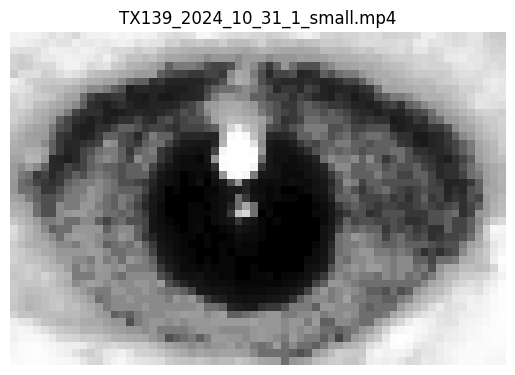

Computing subsampled mean...
Computed subsampled mean at 0.35s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.14sec
computed svd chunk 1 / 15, time  6.84sec
computed svd chunk 2 / 15, time  12.00sec
computed svd chunk 3 / 15, time  17.46sec
computed svd chunk 4 / 15, time  22.68sec
computed svd chunk 5 / 15, time  28.98sec
computed svd chunk 6 / 15, time  34.67sec
computed svd chunk 7 / 15, time  41.37sec
computed svd chunk 8 / 15, time  46.28sec
computed svd chunk 9 / 15, time  51.45sec
computed svd chunk 10 / 15, time  56.47sec
computed svd chunk 11 / 15, time  61.80sec
computed svd chunk 12 / 15, time  66.90sec
computed svd chunk 13 / 15, time  72.29sec
computed svd chunk 14 / 15, time  77.62sec
Computed subsampled SVD at 95.26s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 449, time  95.34sec
computed video chunk 10 / 449, time  95.90sec
computed video chunk 20 / 449, time  96.45sec
computed video chunk 30 / 449, time  97.02sec
computed video chunk 40

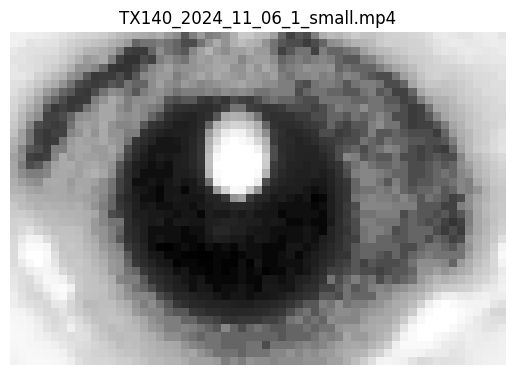

Computing subsampled mean...
Computed subsampled mean at 0.30s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.13sec
computed svd chunk 1 / 15, time  5.92sec
computed svd chunk 2 / 15, time  11.00sec
computed svd chunk 3 / 15, time  16.03sec
computed svd chunk 4 / 15, time  21.17sec
computed svd chunk 5 / 15, time  27.44sec
computed svd chunk 6 / 15, time  32.18sec
computed svd chunk 7 / 15, time  37.25sec
computed svd chunk 8 / 15, time  42.61sec
computed svd chunk 9 / 15, time  47.43sec
computed svd chunk 10 / 15, time  52.46sec
computed svd chunk 11 / 15, time  57.59sec
computed svd chunk 12 / 15, time  62.20sec
computed svd chunk 13 / 15, time  67.54sec
computed svd chunk 14 / 15, time  72.66sec
Computed subsampled SVD at 90.85s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 722, time  90.92sec
computed video chunk 10 / 722, time  91.42sec
computed video chunk 20 / 722, time  91.98sec
computed video chunk 30 / 722, time  92.54sec
computed video chunk 40

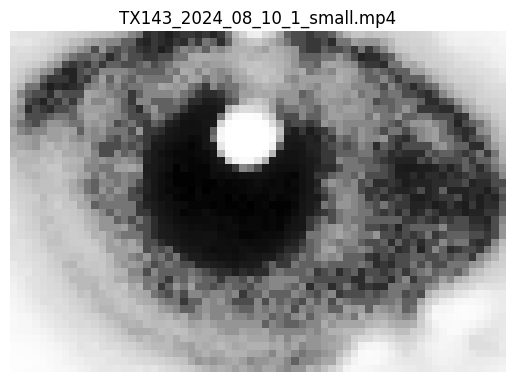

Computing subsampled mean...
Computed subsampled mean at 0.28s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.15sec
computed svd chunk 1 / 15, time  5.68sec
computed svd chunk 2 / 15, time  10.76sec
computed svd chunk 3 / 15, time  17.41sec
computed svd chunk 4 / 15, time  22.85sec
computed svd chunk 5 / 15, time  28.46sec
computed svd chunk 6 / 15, time  33.60sec
computed svd chunk 7 / 15, time  39.07sec
computed svd chunk 8 / 15, time  43.33sec
computed svd chunk 9 / 15, time  48.68sec
computed svd chunk 10 / 15, time  54.37sec
computed svd chunk 11 / 15, time  59.46sec
computed svd chunk 12 / 15, time  64.50sec
computed svd chunk 13 / 15, time  69.89sec
computed svd chunk 14 / 15, time  75.03sec
Computed subsampled SVD at 94.81s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 499, time  94.91sec
computed video chunk 10 / 499, time  95.48sec
computed video chunk 20 / 499, time  96.05sec
computed video chunk 30 / 499, time  96.64sec
computed video chunk 40

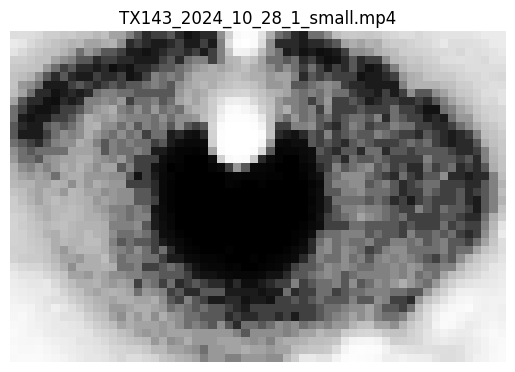

Computing subsampled mean...
Computed subsampled mean at 0.23s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.13sec
computed svd chunk 1 / 15, time  5.70sec
computed svd chunk 2 / 15, time  10.78sec
computed svd chunk 3 / 15, time  16.52sec
computed svd chunk 4 / 15, time  22.16sec
computed svd chunk 5 / 15, time  27.45sec
computed svd chunk 6 / 15, time  32.60sec
computed svd chunk 7 / 15, time  37.89sec
computed svd chunk 8 / 15, time  44.98sec
computed svd chunk 9 / 15, time  51.14sec
computed svd chunk 10 / 15, time  56.33sec
computed svd chunk 11 / 15, time  61.31sec
computed svd chunk 12 / 15, time  66.59sec
computed svd chunk 13 / 15, time  71.75sec
computed svd chunk 14 / 15, time  76.74sec
Computed subsampled SVD at 95.49s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 357, time  95.59sec
computed video chunk 10 / 357, time  96.07sec
computed video chunk 20 / 357, time  96.56sec
computed video chunk 30 / 357, time  97.08sec
computed video chunk 40

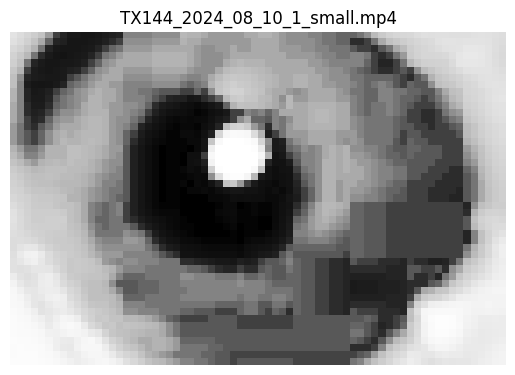

Computing subsampled mean...
Computed subsampled mean at 0.14s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.11sec
computed svd chunk 1 / 15, time  5.65sec
computed svd chunk 2 / 15, time  10.70sec
computed svd chunk 3 / 15, time  16.45sec
computed svd chunk 4 / 15, time  21.64sec
computed svd chunk 5 / 15, time  28.11sec
computed svd chunk 6 / 15, time  33.66sec
computed svd chunk 7 / 15, time  38.49sec
computed svd chunk 8 / 15, time  43.51sec
computed svd chunk 9 / 15, time  48.65sec
computed svd chunk 10 / 15, time  54.04sec
computed svd chunk 11 / 15, time  59.05sec
computed svd chunk 12 / 15, time  64.76sec
computed svd chunk 13 / 15, time  69.92sec
computed svd chunk 14 / 15, time  75.33sec
Computed subsampled SVD at 93.11s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 509, time  93.20sec
computed video chunk 10 / 509, time  93.80sec
computed video chunk 20 / 509, time  94.39sec
computed video chunk 30 / 509, time  94.94sec
computed video chunk 40

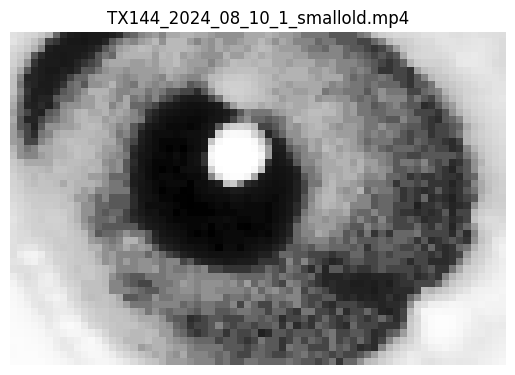

Computing subsampled mean...
Computed subsampled mean at 0.28s
Computing subsampled SVD...
computed svd chunk 0 / 15, time  0.14sec
computed svd chunk 1 / 15, time  5.18sec
computed svd chunk 2 / 15, time  10.90sec
computed svd chunk 3 / 15, time  16.75sec
computed svd chunk 4 / 15, time  22.35sec
computed svd chunk 5 / 15, time  27.41sec
computed svd chunk 6 / 15, time  32.61sec
computed svd chunk 7 / 15, time  38.08sec
computed svd chunk 8 / 15, time  43.26sec
computed svd chunk 9 / 15, time  49.32sec
computed svd chunk 10 / 15, time  55.24sec
computed svd chunk 11 / 15, time  60.21sec
computed svd chunk 12 / 15, time  65.36sec
computed svd chunk 13 / 15, time  71.92sec
computed svd chunk 14 / 15, time  76.80sec
Computed subsampled SVD at 95.55s
Computing ROIs and/or motSVD/movSVD
computed video chunk 0 / 509, time  95.66sec
computed video chunk 10 / 509, time  96.21sec
computed video chunk 20 / 509, time  96.81sec
computed video chunk 30 / 509, time  97.39sec
computed video chunk 40

In [4]:
small_video_files = sorted(glob(os.path.join(data_path, '**', '*small*.mp4'), recursive=True))

%matplotlib inline
for video in small_video_files[1:]:
    # display a random frame after contrast adjustment (histogram equalization)
    cap = cv2.VideoCapture(video)
    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, np.random.randint(0, max(n_frames, 1)))
    ret, frame = cap.read()
    cap.release()
    if ret:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        adjusted = cv2.equalizeHist(gray)
        fig, ax = plt.subplots(1, 1)
        ax.imshow(adjusted, cmap='gray')
        ax.set_title(os.path.basename(video))
        ax.axis('off')
        plt.show()
    # process svd, saving to the same folder as the video file
    savename = process.run([[video]], motSVD=True, movSVD=True, savepath=os.path.dirname(video))

    # rename output using *eyesvd* name
    eyesvd_path = os.path.splitext(video.replace('full', 'eyesvd'))[0] + '_proc.npy'
    if savename != eyesvd_path:
        os.replace(savename, eyesvd_path)
    print("Output saved in", eyesvd_path)
